In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [15]:
## Load the lab reference data
lab = pd.read_csv("lab_ref_co2_5min_101026_131026.csv")
lab.datetime_utc = pd.to_datetime(lab.datetime_utc, utc=True)  # Convert to datetime
lab.set_index("datetime_utc", inplace=True)  # Set the datetime as the index (useful for merging later)

<Axes: xlabel='datetime_utc'>

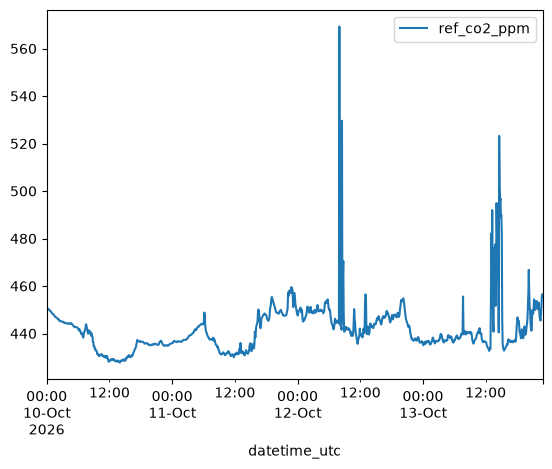

In [16]:
## view the lab data
lab.plot(y="ref_co2_ppm")

In [17]:
# load a sensor data file
sensor = pd.read_csv('export.csv')

# NB there was a timezone error in the sensor data, so we need to adjust the time by -1 hour to match the lab data
sensor['UTC Date/Time'] = pd.to_datetime(sensor['UTC Date/Time'], utc=True) - pd.Timedelta(hours=1)  # Convert to datetime and adjust for timezone error

sensor.set_index('UTC Date/Time', inplace=True)  # Set the datetime as the index (useful for merging later)

(29864820.0, 29865240.0)

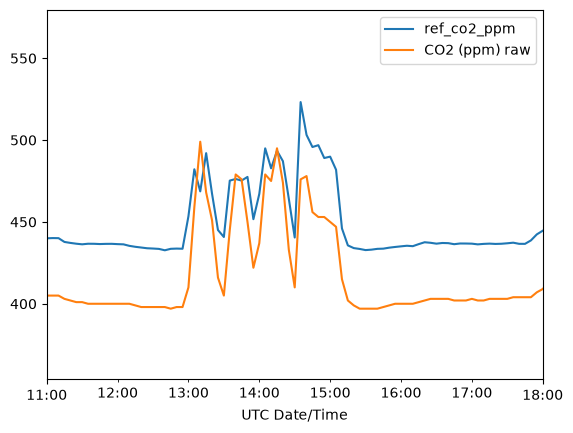

In [29]:
# check the time alignment by looking at a spike
ax = lab.plot(y="ref_co2_ppm")
sensor.plot(y='CO2 (ppm) raw', ax=ax)
ax.set_xlim(pd.Timestamp('2026-10-13 11:00'), pd.Timestamp('2026-10-13 18:00'))

In [30]:
# merge the lab and sensor data into a single dataframe for analysis
combined = pd.concat([lab['ref_co2_ppm'], sensor['CO2 (ppm) raw']], axis=1)
## NB this only works because we set the row indices to datetime for both datasets

/var/folders/bb/w1bxf7tn7s5d6kmbffb4stmw0000gn/T/ipykernel_3467/858839367.py:2: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  combined = pd.concat([lab['ref_co2_ppm'], sensor['CO2 (ppm) raw']], axis=1)


<Axes: >

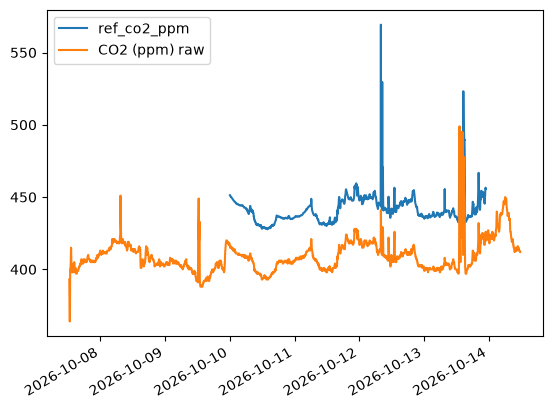

In [31]:
# view the combined data
combined.plot(y=['ref_co2_ppm', 'CO2 (ppm) raw'])

<Axes: >

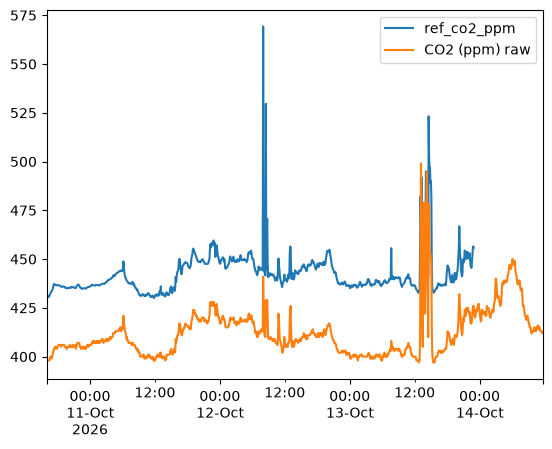

In [33]:
combined = combined.loc['2026-10-10 16:00':]  # remove all data before the spike, where the sensor had a different offset

# view the combined data
combined.plot(y=['ref_co2_ppm', 'CO2 (ppm) raw'])

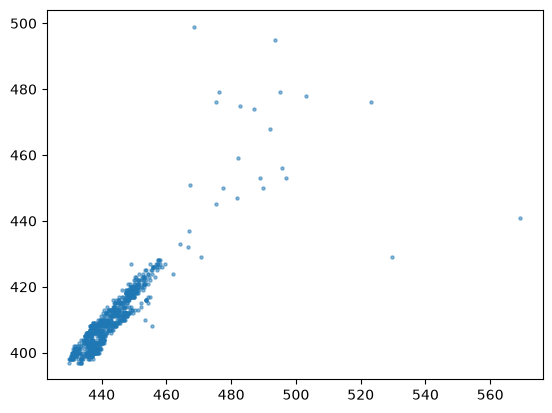

In [35]:
# view the combined data
plt.scatter(combined['ref_co2_ppm'], combined['CO2 (ppm) raw'], label='raw', s=5, alpha=0.5)

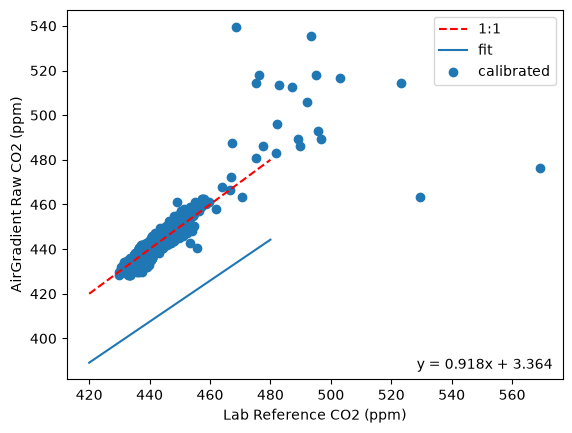

In [36]:

# draw 1:1 line for reference
plt.plot([420,480], [420, 480], 'r--', label='1:1')

# drop na values
combined = combined.dropna()

# fit a linear regression to the data (note `cov` gives the covariance matrix of the fit parameters, which can be used to estimate uncertainties)
p, cov = np.polyfit(combined['ref_co2_ppm'], combined['CO2 (ppm) raw'], 1, cov=True)

# plot the fit line
nx = np.linspace(420, 480, 100)
plt.plot(nx, np.polyval(p,nx), label='fit')

# plot the corrected data (i.e. the sensor data after applying the linear regression correction)
plt.scatter(combined['ref_co2_ppm'], (combined['CO2 (ppm) raw'] - p[1]) / p[0], label='calibrated')

plt.text(0.98, 0.02, f"y = {p[0]:.3f}x + {p[1]:.3f}", transform=plt.gca().transAxes, ha='right', va='bottom')

plt.xlabel('Lab Reference CO2 (ppm)')
plt.ylabel('AirGradient Raw CO2 (ppm)')
plt.legend()